In [ ]:
#Case Study : Student Performance System

In [ ]:
#Create the Classroom dataset
#Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
students = pd.DataFrame({
    "student_id" : ["S101","S102","S103","S104","S105"],
    "course" : ["DA","PFS","DA","PFS","DA"],
    "hours" : [5,8,3,10,6],
    "score" : [55,70,40,85,65],
    "satisfaction" : ["satisfied","Very Satisfied","Neutral","Satisfied","Very Satisfied"]
})
students

,student_id,course,hours,score,satisfaction
0,S101,DA,5,55,satisfied
1,S102,PFS,8,70,Very Satisfied
2,S103,DA,3,40,Neutral
3,S104,PFS,10,85,Satisfied
4,S105,DA,6,65,Very Satisfied


In [ ]:
print("Shape:",students.shape)
print(type(students))
print(students.dtypes)
print(students.size)
print(students.ndim)
print(type(students.values))
print("Missing Values:",students.isna().sum())

Shape: (5, 5)
<class 'pandas.core.frame.DataFrame'>
student_id      object
course          object
hours            int64
score            int64
satisfaction    object
dtype: object
25
2
<class 'numpy.ndarray'>
Missing Values: student_id      0
course          0
hours           0
score           0
satisfaction    0
dtype: int64


In [ ]:
#Count Categories and Summarise Numerical Columns
print("Students per course count:",students['course'].value_counts())
print(students[['hours','score']].describe()) #Descriptive Stats information
#Observe Students Proportion
print((students['course'] == "DA").mean())
print((students['course'] == "PFS").mean())

Students per course count: course
DA     3
PFS    2
Name: count, dtype: int64
           hours      score
count   5.000000   5.000000
mean    6.400000  63.000000
std     2.701851  16.807736
min     3.000000  40.000000
25%     5.000000  55.000000
50%     6.000000  65.000000
75%     8.000000  70.000000
max    10.000000  85.000000
0.6
0.4


In [ ]:
#Python Central tendency and Interpretation
values = np.array([12,15,15,18,20,22,22,22,25,90])
mean_value = np.mean(values)
median_value = np.median(values)
mode_value = pd.Series(values).mode().tolist()
print("Mean:",mean_value)
print("Median",median_value)
print("Mode",mode_value)
print("Sorted Vlaues",np.sort(values))

Mean: 26.1
Median 21.0
Mode [22]
Sorted Vlaues [12 15 15 18 20 22 22 22 25 90]


In [ ]:
#manual Calculation --> Sensitivity in the information -->Spread Outliers and Relationships

In [ ]:
#Day 2 03/11/26

In [ ]:
students.columns

Index(['student_id', 'course', 'hours', 'score', 'satisfaction'], dtype='object')

In [ ]:
#manual Calculation --> Sensitivity in the information -->Spread Outliers and Relationships
#Connect the library result to the manual calculation
values = np.array([12,15,15,18,20,22,22,22,25,90])
total = np.sum(values)
print(total)

261


In [ ]:
count = len(values)
print(count)

10


In [ ]:
manual_mean = total / count
print(f'Manual mean calculation result is {manual_mean}')

Manual mean calculation result is 26.1


In [ ]:
#manual Median calculation
ordered = np.sort(values)
print(ordered)
middle = count // 2 #10 // 2 --> 5
manual_median = (ordered[middle-1]+ordered[middle])/ 2 #Python indexing starts at 0
print("Manual_Median:",manual_median)

[12 15 15 18 20 22 22 22 25 90]
Manual_Median: 21.0


In [ ]:
#Demonstrate the sensitivity to an extreme value
print(values)
#Exclude 90 only for a comparison,retaining the original array
comparision_values = values[values!=90]
comparision_values
print("Original Mean",np.mean(values))
print("Mean Excludion 90:",np.mean(comparision_values))
#Expected 26.1 and 19.0 --> The Boolean mask selects values that differ from 90,

[12 15 15 18 20 22 22 22 25 90]
Original Mean 26.1
Mean Excludion 90: 19.0


In [ ]:
#Python spread outliers and relationships
scores_a = np.array([58,60,62])
scores_b = np.array([20,60,100])
for name,scores in [("Akash",scores_a),("Sanjay",scores_b)]:
  print(name,scores)
  print(name,"Mean = ",np.mean(scores),
        "Range:",np.max(scores)-np.min(scores),
        "Population Std",round(np.std(scores),2))
  #Standard Deviation --> It quantifies the amount of variation or spread in a set of
  #data points relative to its mean
  #Low Standard Deviation --> Indicates that the datapoints tend to be very close to mean
  #High Standard Deviation --> Indicates that the data pooints are spread over a wider range

Akash [58 60 62]
Akash Mean =  60.0 Range: 4 Population Std 1.63
Sanjay [ 20  60 100]
Sanjay Mean =  60.0 Range: 80 Population Std 32.66


In [ ]:
#Flag unusual values using the IQR (Inter Quartile Range)
print(values)
q1,q3 = np.percentile(values,[25,75])
print(q1)
print(q3)
iqr = q3 - q1 #Q1 -> Lower quartile,Q3 --> Upper Quartile
print(iqr)
lower = q1 - (1.5)*iqr
upper = q3 + (1.5)*iqr
print(lower)
print(upper)
flagged = values[(values < lower) | (values > upper)]
print("Q1:",q1,"Q3:",q3,"IQR:",iqr)
print("Fences:",lower,upper)
print("Flagged Value(s) [Outliers]:",flagged)

[12 15 15 18 20 22 22 22 25 90]
15.75
22.0
6.25
6.375
31.375
Q1: 15.75 Q3: 22.0 IQR: 6.25
Fences: 6.375 31.375
Flagged Value(s) [Outliers]: [90]


Pearson Correlation: 0.985


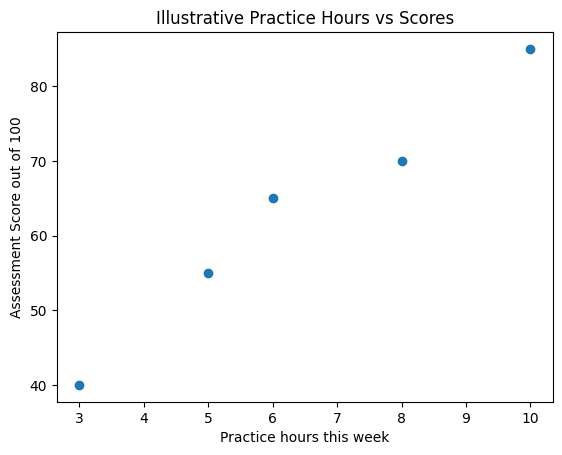

In [ ]:
#Exploring Numerical Relationship
import matplotlib.pyplot as plt
result = students["hours"].corr(students['score']) #Pearson Correlation
#Pearson Correlation (r) -->It is a statistical measure that quantifies the
#strength and direction of a linear relationship between two continuous variables
#+1.0 --> Perfectly positive -->As variable x increases,y also increases in aperfect
#st.line
#-1.0 -->Perfectly negative --> As variable x increases,variable y decreases
#0.0 (No linear correlation) --> there is no linear relation b/w variables
result
print("Pearson Correlation:",round(result,3))
plt.scatter(students["hours"],students['score'])
plt.xlabel("Practice hours this week")
plt.ylabel("Assessment Score out of 100")
plt.title("Illustrative Practice Hours vs Scores")
plt.show()

In [ ]:
#Datatypes,Central Tendency and a First look at spread
#Variance,Standard Deviation,Quartiles and the IQR rule

#Range --> First measure of spread  --> Range = Maximum - Minimum
#Student A --> Scores --> 58,60,62 --> Mean --> 60 --> Deviations --> 58-60 = -2, 60-60 = 0, 62-60 = 2
#Student B --> Scores --> 20,60,200 --> Mean -->60 --> Deviations -->-40,0,40
#For both students,the deviations add to zero.Averaged signed deviations would hide the
#spread.Squaring makes the contributions non negative and gives greater weight to larger
#deviations
#Scores -> A --. deviation as follows
'''
Score x           Mean.             Deviation (x-mean)                  Squared Deviations
58                 60                     -2                                   4
60                 60                      0                                   0
62                 60                      2                                   4

Total Sqd deviation = 4 + 0 + 4 = 8 --> Population variance = 8 / 3 = 2.667 marks squared
Population Variance = Sum of Squared deviations / N
Population Standard deviation = Square root[Summation (xi - u)**2] / N #xi --> each individual value
u --> population mean
Population Std Deviation --> sqrt(2.667) --> 1.663 marks
'''
print(scores_a)
print(scores_b)
mean_a = np.mean(scores_a)
print(mean_a)
deviations = scores_a - mean_a
print(deviations)
squared_deviations = deviations**2
squared_total = np.sum(squared_deviations)
print(squared_total)
variance_a = squared_total / len(scores_a)
print(variance_a)
std_a = np.sqrt(variance_a)
print(std_a)

[58 60 62]
[ 20  60 100]
60.0
[-2.  0.  2.]
8.0
2.6666666666666665
1.632993161855452
